# German Traffic Sign Recognition with a CNN

A convolutional neural network that classifies the 43 sign classes of the
[GTSRB benchmark](https://benchmark.ini.rub.de/gtsrb_news.html).

**How this notebook evaluates the model**

- GTSRB stores each physical sign as a *track* of ~30 near-identical frames. Training and
  validation images are therefore split **by track**, so no sign appears on both sides.
- The final score is measured on the **official `Test.csv` set** (12,630 images), which the
  model never sees during training or model selection.
- Each image is **cropped to its sign bounding box** (`Roi.*` columns) before resizing.

The notebook runs on Google Colab, Kaggle or a local machine.

## 1. Setup and configuration

In [1]:
import os
import random
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
import keras
from keras import layers

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (CPU only)")

SEED = 42
keras.utils.set_random_seed(SEED)  # seeds Python, NumPy and TensorFlow

IMAGE_SIZE = (32, 32)
NUM_CLASSES = 43
BATCH_SIZE = 64
EPOCHS = int(os.environ.get("EPOCHS", 50))
VAL_FRACTION = 0.15
MODEL_PATH = "gtsrb_cnn.keras"

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SIGN_NAMES = [
    "Speed limit (20km/h)",                         # 0
    "Speed limit (30km/h)",                         # 1
    "Speed limit (50km/h)",                         # 2
    "Speed limit (60km/h)",                         # 3
    "Speed limit (70km/h)",                         # 4
    "Speed limit (80km/h)",                         # 5
    "End of speed limit (80km/h)",                  # 6
    "Speed limit (100km/h)",                        # 7
    "Speed limit (120km/h)",                        # 8
    "No passing",                                   # 9
    "No passing for vehicles over 3.5 tons",        # 10
    "Right-of-way at the next intersection",        # 11
    "Priority road",                                # 12
    "Yield",                                        # 13
    "Stop",                                         # 14
    "No vehicles",                                  # 15
    "Vehicles over 3.5 tons prohibited",            # 16
    "No entry",                                     # 17
    "General caution",                              # 18
    "Dangerous curve to the left",                  # 19
    "Dangerous curve to the right",                 # 20
    "Double curve",                                 # 21
    "Bumpy road",                                   # 22
    "Slippery road",                                # 23
    "Road narrows on the right",                    # 24
    "Road work",                                    # 25
    "Traffic signals",                              # 26
    "Pedestrians",                                  # 27
    "Children crossing",                            # 28
    "Bicycles crossing",                            # 29
    "Beware of ice/snow",                           # 30
    "Wild animals crossing",                        # 31
    "End of all speed and passing limits",          # 32
    "Turn right ahead",                             # 33
    "Turn left ahead",                              # 34
    "Ahead only",                                   # 35
    "Go straight or right",                         # 36
    "Go straight or left",                          # 37
    "Keep right",                                   # 38
    "Keep left",                                    # 39
    "Roundabout mandatory",                         # 40
    "End of no passing",                            # 41
    "End of no passing by vehicles over 3.5 tons",  # 42
]
assert len(SIGN_NAMES) == NUM_CLASSES

## 2. Get the dataset

The dataset is the Kaggle mirror
[`meowmeowmeowmeowmeow/gtsrb-german-traffic-sign`](https://www.kaggle.com/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign).

- **Already downloaded?** Set the `GTSRB_DIR` environment variable to the folder containing
  `Train.csv`, `Test.csv` and `Meta.csv`.
- **Otherwise** the cell downloads it with [`kagglehub`](https://github.com/Kaggle/kagglehub).
  If Kaggle asks you to sign in, provide your credentials through **Colab Secrets**
  (`KAGGLE_USERNAME`, `KAGGLE_KEY`), environment variables, or `~/.kaggle/kaggle.json`.

> ⚠️ Never upload `kaggle.json` with `files.upload()` or print it: the output is saved in the
> notebook and becomes public when the notebook is pushed to GitHub.

In [3]:
DATA_DIR = os.environ.get("GTSRB_DIR")

if DATA_DIR is None:
    try:
        import kagglehub
    except ImportError:
        %pip install -q kagglehub
        import kagglehub
    DATA_DIR = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")

print("Dataset folder:", DATA_DIR)
print(sorted(os.listdir(DATA_DIR)))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Dataset folder: /kaggle/input/gtsrb-german-traffic-sign
['Meta', 'Meta.csv', 'Test', 'Test.csv', 'Train', 'Train.csv', 'meta', 'test', 'train']


## 3. Load the metadata

In [4]:
train_df = pd.read_csv(os.path.join(DATA_DIR, "Train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "Test.csv"))
meta_df = pd.read_csv(os.path.join(DATA_DIR, "Meta.csv"))

# Train paths look like Train/<class>/<class>_<track>_<frame>.png.
# The track id identifies one physical sign, so it is used to group frames when splitting.
train_df["Track"] = train_df["Path"].str.extract(r"/(\d+_\d+)_\d+\.png$")[0]
assert train_df["Track"].notna().all(), "Unexpected Train.csv path format"

print(f"Train images: {len(train_df):,} from {train_df['Track'].nunique():,} physical signs")
print(f"Official test images: {len(test_df):,}")
train_df.head()

Train images: 39,209 from 1,307 physical signs
Official test images: 12,630


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path,Track
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png,00020_00000
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png,00020_00000
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png,00020_00000
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png,00020_00000
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png,00020_00000


## 4. Exploratory data analysis

### Class distribution

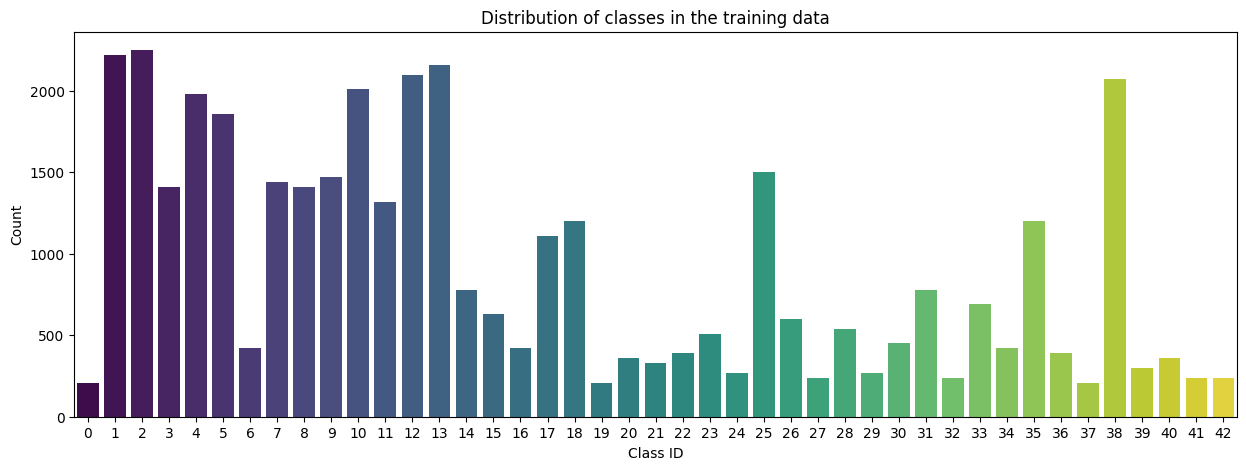

In [5]:
plt.figure(figsize=(15, 5))
sns.countplot(x="ClassId", hue="ClassId", data=train_df, palette="viridis", legend=False)
plt.title("Distribution of classes in the training data")
plt.xlabel("Class ID")
plt.ylabel("Count")
plt.show()

### Reference image for each class (`Meta.csv`)

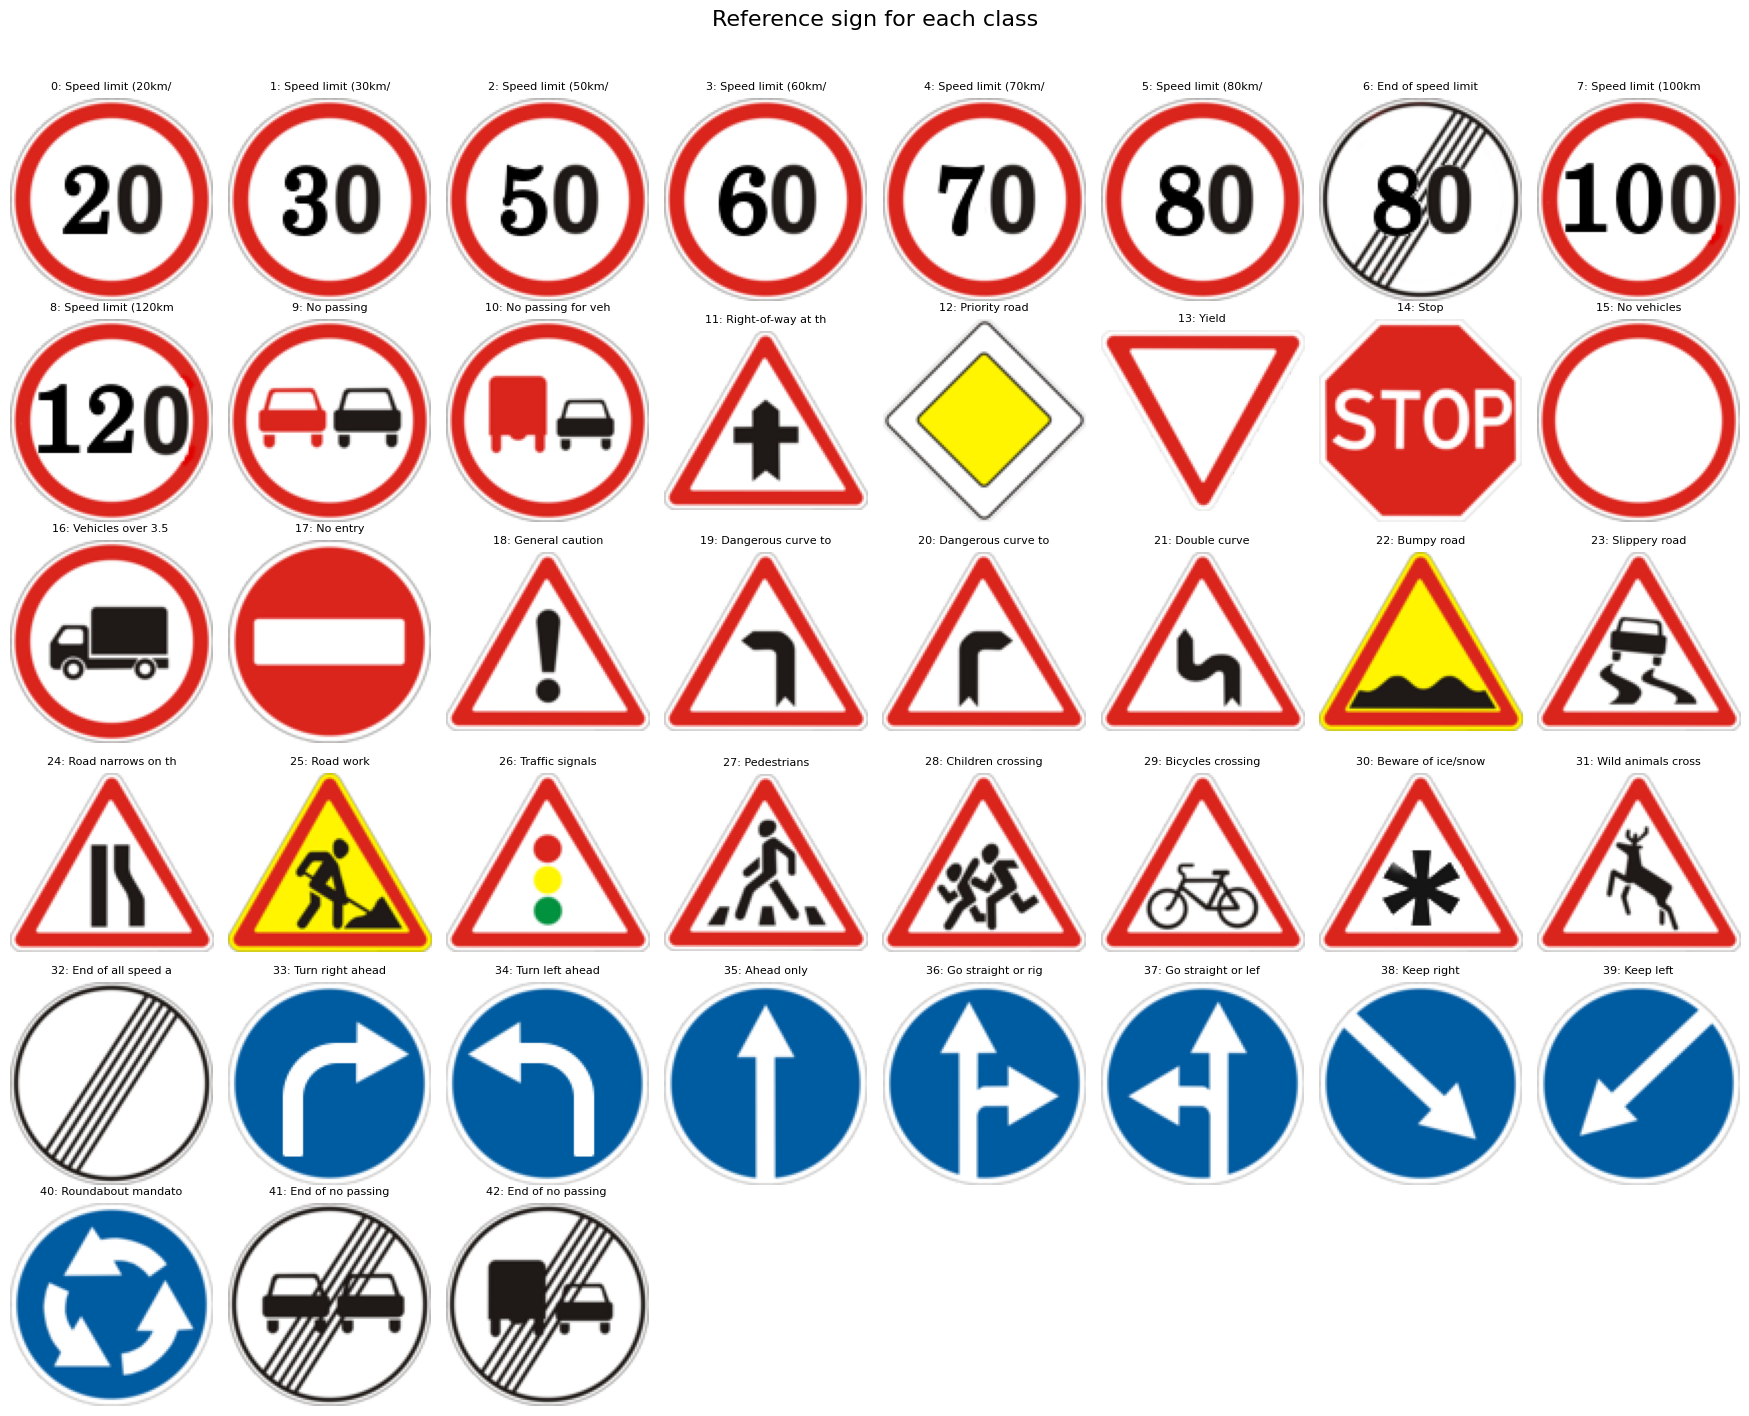

In [6]:
cols = 8
rows = int(np.ceil(NUM_CLASSES / cols))
plt.figure(figsize=(cols * 2.2, rows * 2.4))
for class_id in range(NUM_CLASSES):
    match = meta_df[meta_df["ClassId"] == class_id]
    if match.empty:
        continue
    plt.subplot(rows, cols, class_id + 1)
    plt.imshow(Image.open(os.path.join(DATA_DIR, match.iloc[0]["Path"])))
    plt.title(f"{class_id}: {SIGN_NAMES[class_id][:18]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Reference sign for each class", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### One real training photo per class

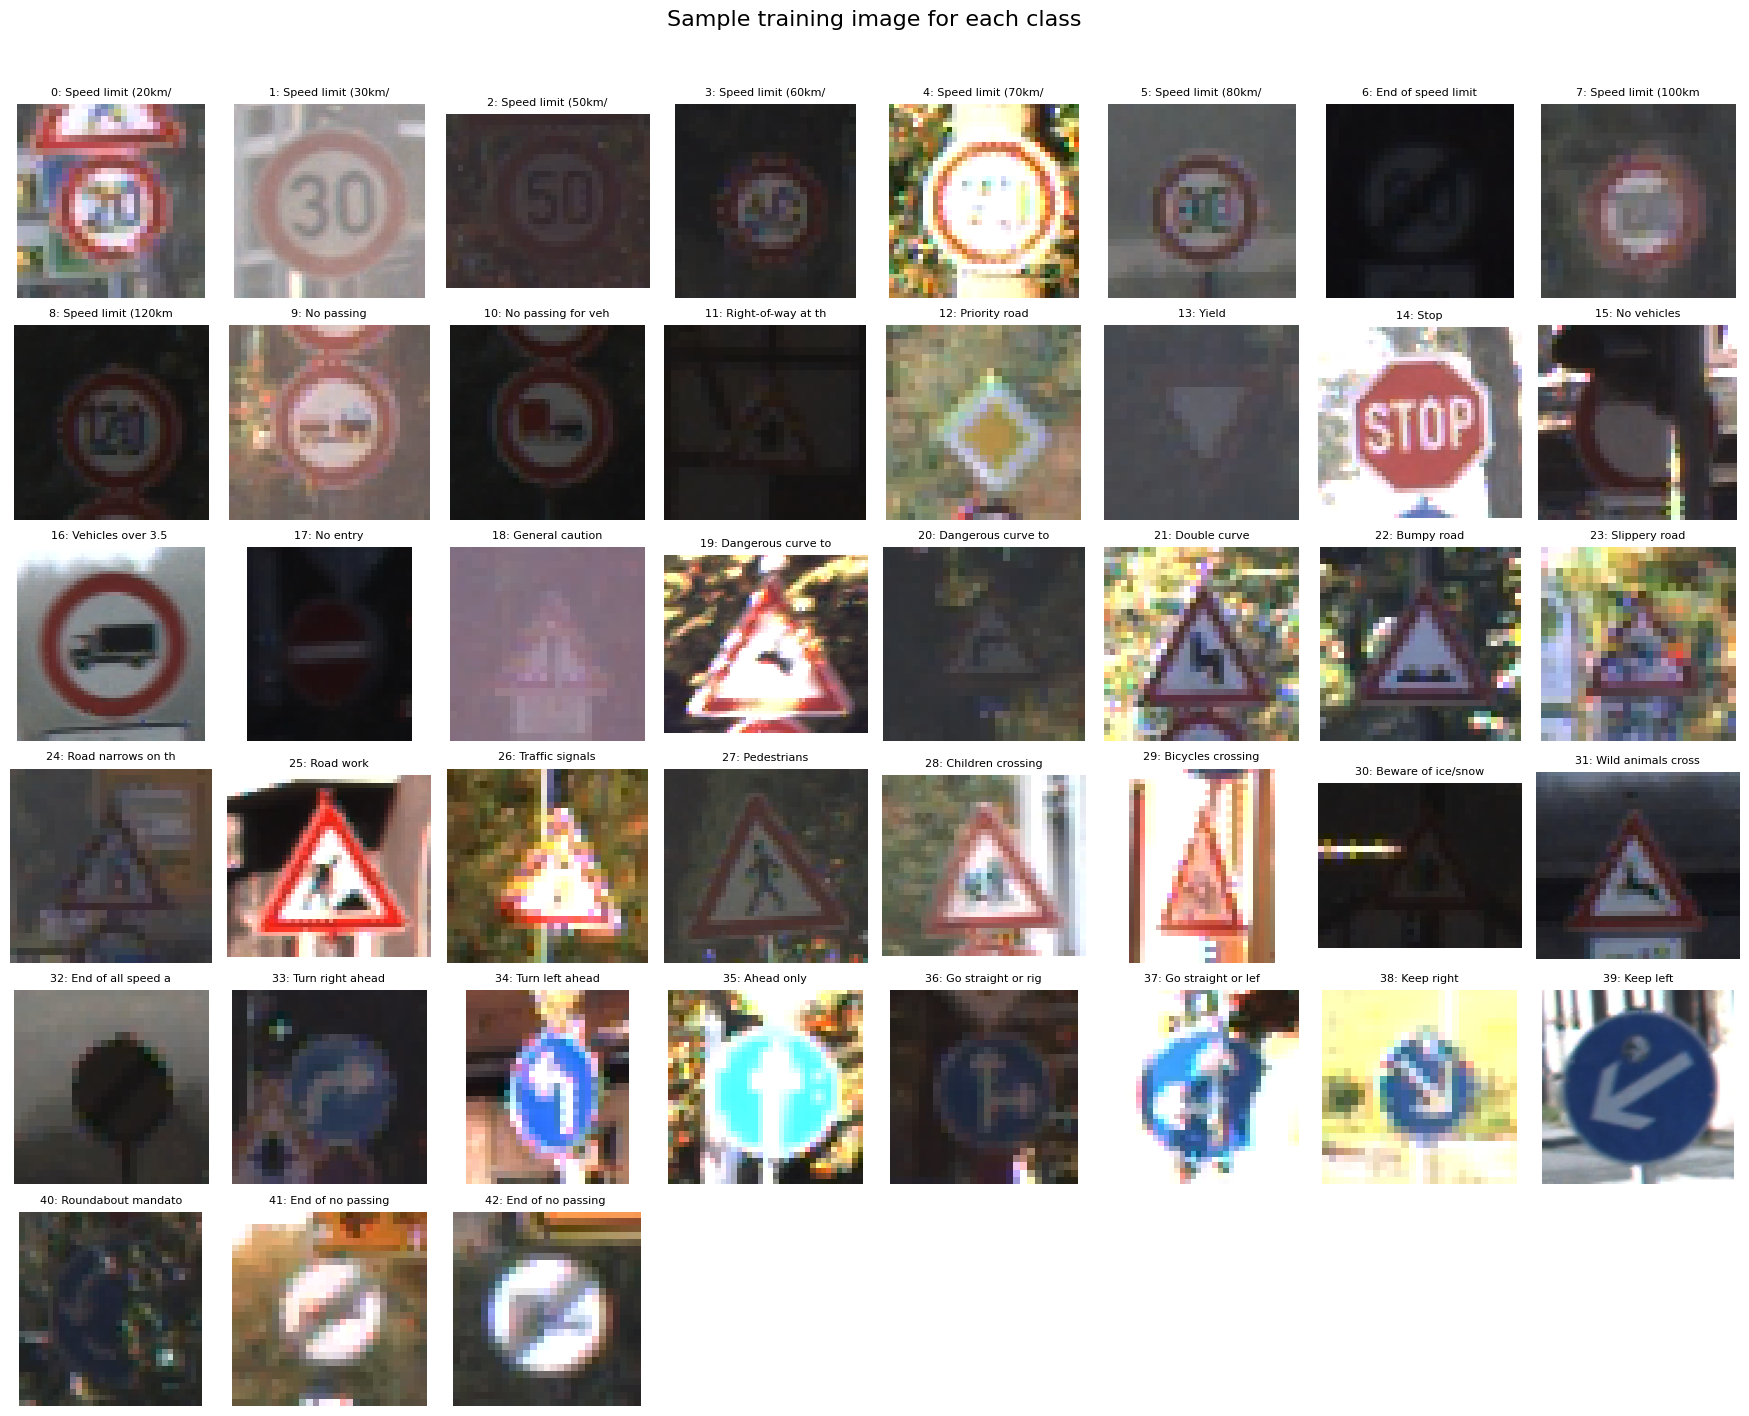

In [7]:
plt.figure(figsize=(cols * 2.2, rows * 2.4))
for class_id in range(NUM_CLASSES):
    sample_path = train_df[train_df["ClassId"] == class_id].iloc[0]["Path"]
    plt.subplot(rows, cols, class_id + 1)
    plt.imshow(Image.open(os.path.join(DATA_DIR, sample_path)))
    plt.title(f"{class_id}: {SIGN_NAMES[class_id][:18]}", fontsize=8)
    plt.axis("off")
plt.suptitle("Sample training image for each class", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 5. Preprocessing

Each image is cropped to its sign bounding box (`Roi.X1`, `Roi.Y1`, `Roi.X2`, `Roi.Y2`),
resized to 32×32 and kept as `uint8`. Scaling to `[0, 1]` happens inside the model, so the
saved model accepts ordinary 0–255 images. Images are loaded in parallel threads.

In [8]:
def load_image(path, box):
    with Image.open(path) as img:
        img = img.convert("RGB").crop(box).resize(IMAGE_SIZE, Image.BILINEAR)
        return np.asarray(img, dtype=np.uint8)


def load_split(df):
    paths = [os.path.join(DATA_DIR, p) for p in df["Path"]]
    # PIL crop boxes are (left, upper, right, lower) with an exclusive right/lower edge.
    boxes = list(zip(df["Roi.X1"], df["Roi.Y1"], df["Roi.X2"] + 1, df["Roi.Y2"] + 1))
    with ThreadPoolExecutor(max_workers=16) as pool:
        images = list(pool.map(load_image, paths, boxes))
    return np.stack(images), df["ClassId"].to_numpy()


X_all, y_all = load_split(train_df)
X_test, y_test = load_split(test_df)
print("Train+val:", X_all.shape, "| Official test:", X_test.shape)

Train+val: (39209, 32, 32, 3) | Official test: (12630, 32, 32, 3)


## 6. Train/validation split by physical sign

For every class, ~15% of its *tracks* (physical signs) are held out for validation, with at
least one track per class. Every frame of a track stays on the same side of the split, so
the validation score reflects signs the model has never seen, and every class is represented.

In [9]:
rng = np.random.default_rng(SEED)
val_tracks = set()
for _, tracks in train_df.groupby("ClassId")["Track"]:
    unique_tracks = tracks.unique()
    n_val = max(1, int(round(VAL_FRACTION * len(unique_tracks))))
    val_tracks.update(rng.choice(unique_tracks, size=n_val, replace=False))

is_val = train_df["Track"].isin(val_tracks).to_numpy()
train_idx, val_idx = np.flatnonzero(~is_val), np.flatnonzero(is_val)

X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val, y_val = X_all[val_idx], y_all[val_idx]

shared = set(train_df["Track"].iloc[train_idx]) & set(train_df["Track"].iloc[val_idx])
assert not shared, "A track leaked across the split"

print(f"Train: {len(X_train):,} images | Validation: {len(X_val):,} images")
print(f"Classes in validation: {len(np.unique(y_val))}/{NUM_CLASSES}")

Train: 33,359 images | Validation: 5,850 images
Classes in validation: 43/43


## 7. Input pipeline and data augmentation

Augmentation (small rotations, shifts and zooms, plus contrast changes) is applied on the
fly to training batches only. Horizontal flips are **not** used, because flipping turns
some signs into other classes (e.g. *Turn left ahead* ↔ *Turn right ahead*).

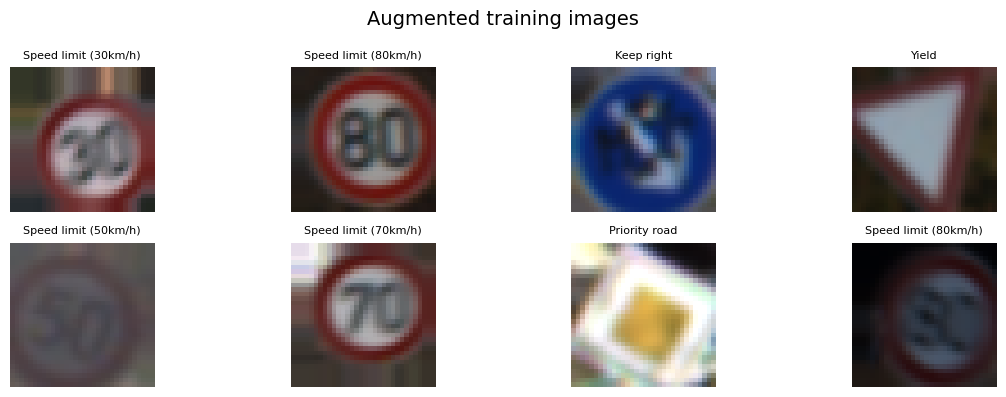

In [10]:
augment = keras.Sequential([
    layers.RandomRotation(15 / 360, fill_mode="nearest"),
    layers.RandomTranslation(0.1, 0.1, fill_mode="nearest"),
    layers.RandomZoom(0.2, fill_mode="nearest"),
    layers.RandomContrast(0.2),
], name="augment")

AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(X, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BATCH_SIZE)
    if training:
        ds = ds.map(
            lambda x, t: (tf.clip_by_value(augment(tf.cast(x, tf.float32), training=True), 0, 255), t),
            num_parallel_calls=AUTOTUNE,
        )
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

aug_batch, aug_labels = next(iter(train_ds))
plt.figure(figsize=(12, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(aug_batch[i].numpy().astype("uint8"))
    plt.title(SIGN_NAMES[int(aug_labels[i])][:20], fontsize=8)
    plt.axis("off")
plt.suptitle("Augmented training images", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Model

In [11]:
model = keras.Sequential([
    keras.Input(shape=(*IMAGE_SIZE, 3)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(NUM_CLASSES, activation="softmax"),
], name="gtsrb_cnn")

# Integer labels with sparse loss: no one-hot encoding needed.
model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "gtsrb_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 10, 10, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       409,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 487,243 (1.86 MB)

 Trainable params: 486,859 (1.86 MB)

 Non-trainable params: 384 (1.50 KB)

## 9. Training

All callbacks watch the same metric (`val_accuracy`), so the checkpoint on disk and the weights
restored by early stopping are the same best epoch. Accuracy is used rather than loss because
validation loss here is driven by a few confidently wrong signs and can rise while accuracy
is still improving.

In [12]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_accuracy", mode="max", patience=10, restore_best_weights=True),
    keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", mode="max", save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_accuracy", mode="max", factor=0.2, patience=5, min_lr=1e-6),
]

# train_ds is already shuffled by tf.data, so Keras-level shuffling is turned off.
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks, shuffle=False)

Epoch 1/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 46s 53ms/step - accuracy: 0.5528 - loss: 1.5706 - val_accuracy: 0.8617 - val_loss: 0.4810 - learning_rate: 0.0010
Epoch 2/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 51s 20ms/step - accuracy: 0.8486 - loss: 0.4808 - val_accuracy: 0.9554 - val_loss: 0.1616 - learning_rate: 0.0010
Epoch 3/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.9129 - loss: 0.2814 - val_accuracy: 0.9762 - val_loss: 0.1033 - learning_rate: 0.0010
Epoch 4/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 19s 17ms/step - accuracy: 0.9369 - loss: 0.2036 - val_accuracy: 0.9721 - val_loss: 0.1230 - learning_rate: 0.0010
Epoch 5/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9492 - loss: 0.1666 - val_accuracy: 0.9812 - val_loss: 0.0980 - learning_rate: 0.0010
Epoch 6/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9590 - loss: 0.1380 - val_accuracy: 0.9687 - val_loss: 0.1395 - learning_rate: 0.0010
Epoch 7/50
522/522 ━━━━━━━━━━━━━━━━━━━━ 10s 19ms/step - accuracy: 0.9623 - l

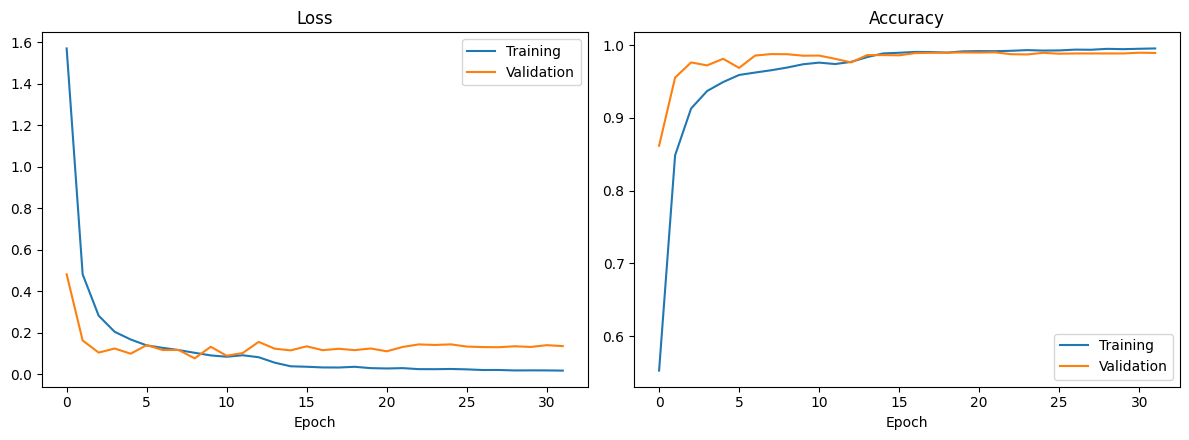

In [13]:
hist = history.history
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(hist["loss"], label="Training")
ax1.plot(hist["val_loss"], label="Validation")
ax1.set(title="Loss", xlabel="Epoch")
ax1.legend()
ax2.plot(hist["accuracy"], label="Training")
ax2.plot(hist["val_accuracy"], label="Validation")
ax2.set(title="Accuracy", xlabel="Epoch")
ax2.legend()
plt.tight_layout()
plt.show()

## 10. Evaluation on the official test set

In [14]:
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Validation accuracy (unseen tracks): {val_acc:.2%}")
print(f"Official test accuracy:               {test_acc:.2%}  (loss {test_loss:.4f})")

y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
print("\nClassification report (official test set):\n")
print(classification_report(
    y_test, y_pred, labels=list(range(NUM_CLASSES)),
    target_names=[f"{i:2d} {name}" for i, name in enumerate(SIGN_NAMES)],
    digits=3, zero_division=0,
))

Validation accuracy (unseen tracks): 99.01%
Official test accuracy:               98.53%  (loss 0.0953)

Classification report (official test set):

                                                precision    recall  f1-score   support

                        0 Speed limit (20km/h)      1.000     1.000     1.000        60
                        1 Speed limit (30km/h)      0.993     0.999     0.996       720
                        2 Speed limit (50km/h)      0.997     0.996     0.997       750
                        3 Speed limit (60km/h)      1.000     0.927     0.962       450
                        4 Speed limit (70km/h)      1.000     0.995     0.998       660
                        5 Speed limit (80km/h)      0.947     0.998     0.972       630
                 6 End of speed limit (80km/h)      1.000     1.000     1.000       150
                       7 Speed limit (100km/h)      1.000     0.998     0.999       450
                       8 Speed limit (120km/h)      0.993 

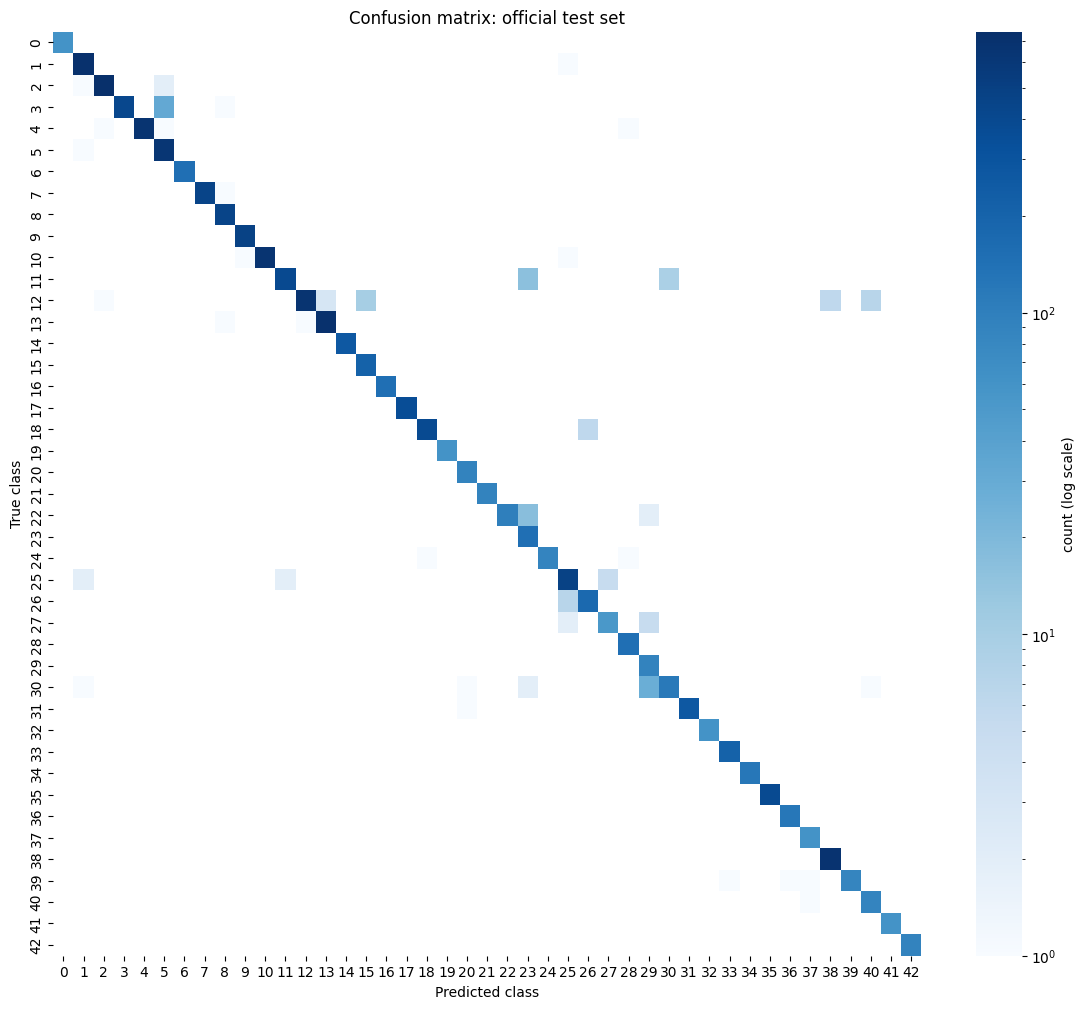

Most common confusions:
    32 x  Speed limit (60km/h)  ->  predicted as  Speed limit (80km/h)
    28 x  Beware of ice/snow  ->  predicted as  Bicycles crossing
    17 x  Bumpy road  ->  predicted as  Slippery road
    16 x  Right-of-way at the next intersection  ->  predicted as  Slippery road
    10 x  Priority road  ->  predicted as  No vehicles
     9 x  Right-of-way at the next intersection  ->  predicted as  Beware of ice/snow
     7 x  Traffic signals  ->  predicted as  Road work
     7 x  Priority road  ->  predicted as  Roundabout mandatory
     6 x  General caution  ->  predicted as  Traffic signals
     6 x  Priority road  ->  predicted as  Keep right


In [15]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(14, 12))
sns.heatmap(cm, mask=cm == 0, cmap="Blues", cbar_kws={"label": "count (log scale)"},
            norm=plt.matplotlib.colors.LogNorm(vmin=1, vmax=max(cm.max(), 2)),
            xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES))
plt.title("Confusion matrix: official test set")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.show()

# The most frequent mistakes, by name
errors = cm.copy()
np.fill_diagonal(errors, 0)
pairs = np.dstack(np.unravel_index(np.argsort(errors, axis=None)[::-1], errors.shape))[0]
print("Most common confusions:")
for t, p in pairs[:10]:
    if errors[t, p] == 0:
        break
    print(f"  {errors[t, p]:4d} x  {SIGN_NAMES[t]}  ->  predicted as  {SIGN_NAMES[p]}")

### Sample predictions and misclassified images

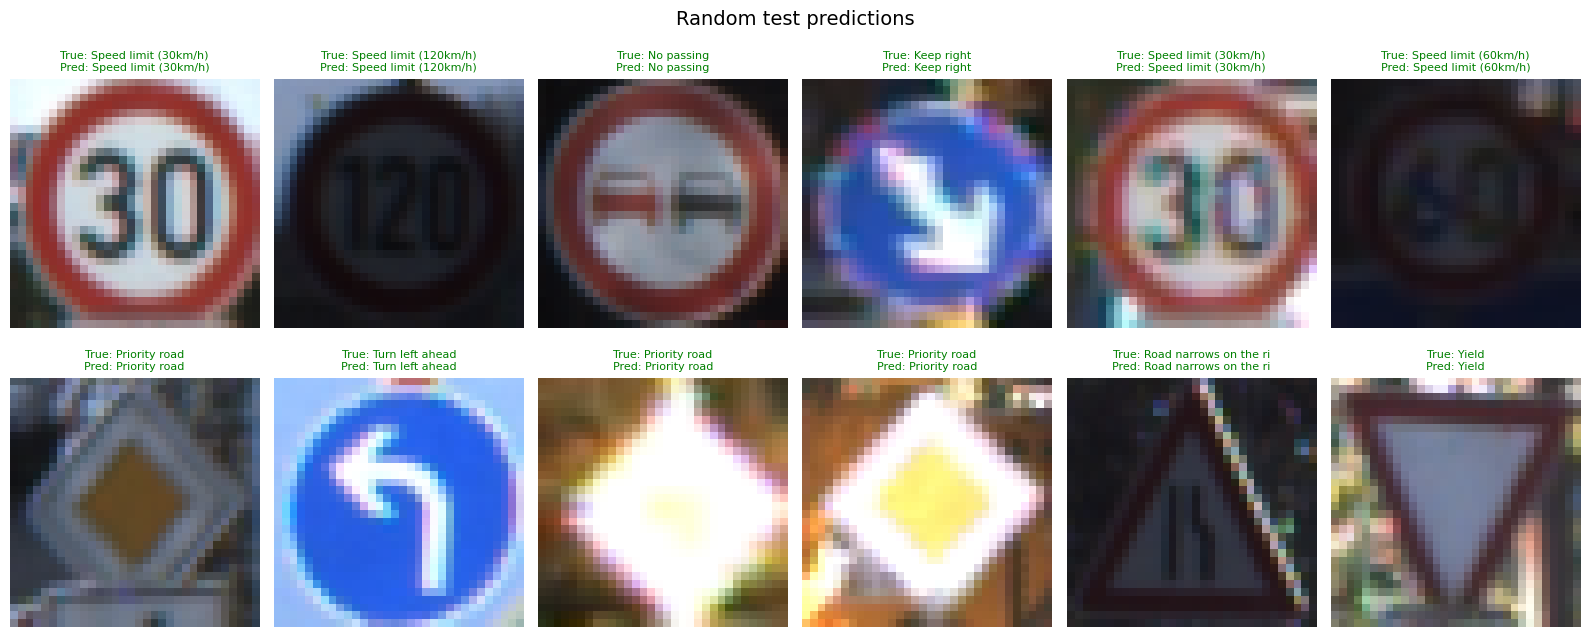

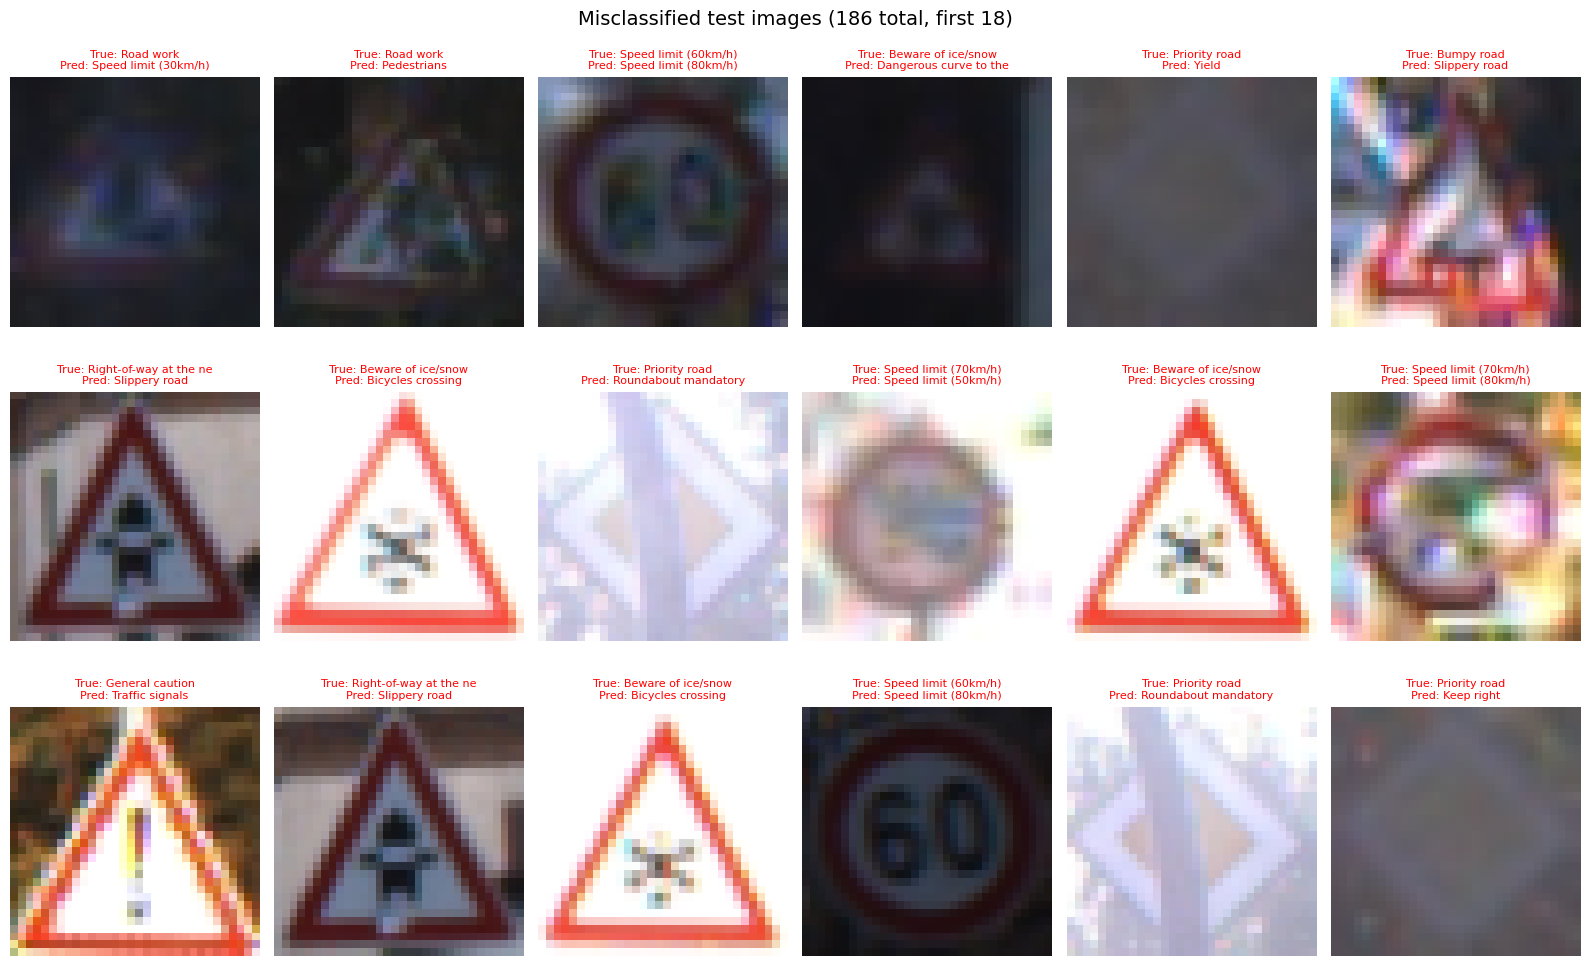

In [16]:
def show_predictions(indices, title):
    if len(indices) == 0:
        print(f"{title}: none")
        return
    n = len(indices)
    plt.figure(figsize=(16, 3.4 * int(np.ceil(n / 6))))
    for k, i in enumerate(indices):
        plt.subplot(int(np.ceil(n / 6)), 6, k + 1)
        plt.imshow(X_test[i])
        correct = y_pred[i] == y_test[i]
        plt.title(f"True: {SIGN_NAMES[y_test[i]][:22]}\nPred: {SIGN_NAMES[y_pred[i]][:22]}",
                  fontsize=8, color="green" if correct else "red")
        plt.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(X_test), size=12, replace=False), "Random test predictions")

wrong = np.flatnonzero(y_pred != y_test)
show_predictions(wrong[:18], f"Misclassified test images ({len(wrong)} total, first 18)")

## 11. Save the model

The best model was already saved to `gtsrb_cnn.keras` by the checkpoint callback. This
cell saves the final (best, restored) weights again and checks that the file reloads.
On Colab it also downloads the file.

In [17]:
model.save(MODEL_PATH)
reloaded = keras.models.load_model(MODEL_PATH)
_, reloaded_acc = reloaded.evaluate(test_ds, verbose=0)
print(f"Saved to {MODEL_PATH}; reloaded test accuracy {reloaded_acc:.2%}")

if IN_COLAB:
    from google.colab import files
    files.download(MODEL_PATH)

Saved to gtsrb_cnn.keras; reloaded test accuracy 98.53%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Using the saved model on a new image

In [18]:
def predict_sign(image_path, model=reloaded):
    """Classify a photo that is already cropped roughly to the sign."""
    img = Image.open(image_path).convert("RGB").resize(IMAGE_SIZE, Image.BILINEAR)
    probs = model.predict(np.asarray(img, dtype=np.uint8)[None], verbose=0)[0]
    top = int(np.argmax(probs))
    return top, SIGN_NAMES[top], float(probs[top])


example = os.path.join(DATA_DIR, test_df.iloc[0]["Path"])
print(predict_sign(example))

(16, 'Vehicles over 3.5 tons prohibited', 1.0)
